# 03. Unified Models as the Baseline

Goal: train the three classifiers on all customers together, using SMOTE to handle class imbalance. These results form the baseline that the segment specific models in notebook 04 are compared against.

Models: logistic regression, random forest, XGBoost.

Metrics: accuracy, precision, recall, F1 score, AUC-ROC.

Outputs:

* ../data/processed/train_test.pkl (shared split reused by notebook 04)
* ../results/tables/unified_results.csv
* ../results/figures/unified_performance.png


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings, joblib
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score)
from imblearn.over_sampling import SMOTE
import xgboost as xgb

SEED = 42
np.random.seed(SEED)

df = pd.read_csv('../data/processed/telco_segmented.csv')
print(f'Loaded: {df.shape}')

Loaded: (7032, 26)


## 1. Prepare features and target

Categorical variables are one hot encoded. The Segment column is kept aside so that notebook 04 can reuse exactly the same train and test split.

In [16]:
cat_cols = ['gender','Partner','Dependents','Contract','PaperlessBilling','PaymentMethod',
            'InternetService','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport',
            'StreamingTV','StreamingMovies','PhoneService','MultipleLines']
num_cols = ['tenure','MonthlyCharges','TotalCharges','NumServices','SeniorCitizen']

X = pd.get_dummies(df[num_cols + cat_cols], drop_first=True).astype(float)
y = df['ChurnBinary']
print(f'Feature matrix: {X.shape}')

Feature matrix: (7032, 31)


## 2. Stratified train and test split

We split 80/20 and stratify on the target so that both sets keep the same churn rate. The segment labels are split at the same time, so notebook 04 uses an identical split and the comparison stays fair.

In [17]:
X_train, X_test, y_train, y_test, seg_train, seg_test = train_test_split(
    X, y, df['Segment'], test_size=0.2, random_state=SEED, stratify=y)
print(f'Train: {len(X_train)}  Test: {len(X_test)}')
print(f'Train churn: {y_train.mean():.3f}  Test churn: {y_test.mean():.3f}')

Train: 5625  Test: 1407
Train churn: 0.266  Test churn: 0.266


## 3. Apply SMOTE to the training data only

This matters. SMOTE is applied only to the training set, after the split. Applying it before the split would leak synthetic information into the test set and inflate the results.

In [18]:
smote = SMOTE(random_state=SEED)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)
print(f'Before SMOTE: {dict(y_train.value_counts())}')
print(f'After  SMOTE: {dict(pd.Series(y_train_sm).value_counts())}')

Before SMOTE: {0: np.int64(4130), 1: np.int64(1495)}
After  SMOTE: {0: np.int64(4130), 1: np.int64(4130)}


## 4. Train the three classifiers

In [19]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1),
    'XGBoost': xgb.XGBClassifier(n_estimators=100, random_state=SEED,
                                 eval_metric='logloss', verbosity=0),
}

results = {}
for name, model in models.items():
    model.fit(X_train_sm, y_train_sm)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    results[name] = {
        'Accuracy':  accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall':    recall_score(y_test, pred),
        'F1':        f1_score(y_test, pred),
        'AUC-ROC':   roc_auc_score(y_test, proba),
    }

results_df = pd.DataFrame(results).T.round(3)
print(results_df)

                     Accuracy  Precision  Recall     F1  AUC-ROC
Logistic Regression     0.732      0.497   0.783  0.609    0.834
Random Forest           0.786      0.614   0.527  0.567    0.817
XGBoost                 0.766      0.561   0.551  0.556    0.812


## 5. Read the results

Accuracy and recall tell different stories here, which is why accuracy alone is misleading on imbalanced data. A model with high recall catches more churners at the cost of precision, and for a retention use case that trade off is usually worth making.

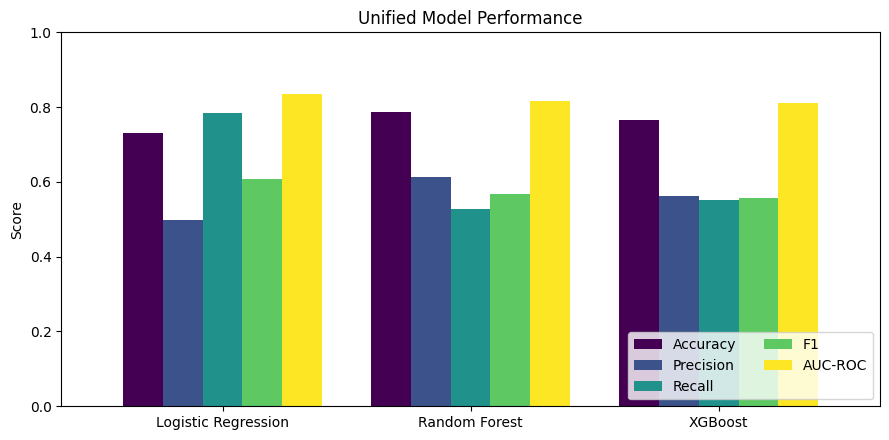

In [20]:
fig, ax = plt.subplots(figsize=(9, 4.5))
results_df.plot(kind='bar', ax=ax, colormap='viridis', width=0.8)
ax.set_ylabel('Score'); ax.set_title('Unified Model Performance')
ax.set_ylim(0, 1); ax.legend(loc='lower right', ncol=2)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../results/figures/unified_performance.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Save the results and the split for notebook 04

In [21]:
results_df.to_csv('../results/tables/unified_results.csv')

# Save the exact split so that notebook 04 makes a fair comparison
joblib.dump({
    'X_train': X_train, 'X_test': X_test,
    'y_train': y_train, 'y_test': y_test,
    'seg_train': seg_train, 'seg_test': seg_test,
    'feature_names': list(X.columns),
}, '../data/processed/train_test.pkl')
print('Saved: unified_results.csv, unified_performance.png, train_test.pkl')

Saved: unified_results.csv, unified_performance.png, train_test.pkl
